In [ ]:
import requests
from bs4 import BeautifulSoup
import csv

#Scraping Code für Metascrap seiten und CSV erstllung
with open("metacritic_genres2012.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["Title", "MetaScore", "Release Date", "Genres"])

    for page in range(1, 6) 
        url = f"https://www.metacritic.com/browse/game/pc/all/2012/metascore/?platform=pc&page={page}"
        headers = {"User-Agent": "Mozilla/5.0"}

        response = requests.get(url, headers=headers)


        soup = BeautifulSoup(response.content, "html.parser")
        games = soup.find_all("div", class_="c-finderProductCard")

        for game in games:
            title_tag = game.find("div", class_="c-finderProductCard_title")
            title = title_tag.text.strip() if title_tag else "No Title"

            metascore_tag = game.find("div", class_="c-siteReviewScore")
            metascore = metascore_tag.text.strip() if metascore_tag else "No MetaScore"

            release_date_tag = game.find("div", class_="c-finderProductCard_meta").find("span")
            release_date = release_date_tag.text.strip() if release_date_tag else "No Release Date"

            url_tag = game.find("a", class_="c-finderProductCard_container")
            game_url = f"https://www.metacritic.com{url_tag['href']}" if url_tag else "No URL"

            if game_url != "No URL":
                try:
                    game_response = requests.get(game_url, headers=headers)
                    game_soup = BeautifulSoup(game_response.content, "html.parser")
                    genre_tags = game_soup.find_all("li", class_="c-genreList_item")
                    genres = ", ".join([
                        genre.find("span", class_="c-globalButton_label").text.strip()
                        for genre in genre_tags
                    ])
                except Exception as e:
                    genres = "Error fetching genres"
            else:
                genres = "No URL"

            writer.writerow([title, metascore, release_date, genres])

print("MetaCritic-Daten mit Genres erfolgreich gespeichert!")

In [ ]:
#Scraping für Opencritc Score Seiten und CSV erstellugn
with open("opencritic_tTopGames2010.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["Title", "Score", "Genres", "Release Date"])

    for page in range(1, 6):  
        url = f"https://opencritic.com/browse/pc/2010?page={page}"
        headers = {"User-Agent": "Mozilla/5.0"}

        response = requests.get(url, headers=headers)
        soup = BeautifulSoup(response.content, "html.parser")

        games = soup.find_all("div", class_="game-row")

        for game in games:
            title_tag = game.find("div", class_="game-name")
            if title_tag:
                title = title_tag.find("a").text.strip() if title_tag.find("a") else "No Title"
            else:
                title = "No Title"

            score_tag = game.find("div", class_="inner-orb")
            score = score_tag.text.strip() if score_tag else "No Score"

            genres_tag = game.find("div", class_="genres")
            genres = genres_tag.text.strip() if genres_tag else "No Genres"

            release_date_tag = game.find("div", class_="first-release-date").find("span")
            release_date = release_date_tag.text.strip() if release_date_tag else "No Release Date"

            writer.writerow([title, score, genres, release_date])

print("Top 100 OpenCritic-Daten erfolgreich gespeichert!")

In [ ]:
#Steam Scraping der Infos und CSV erstellung
url = "https://store.steampowered.com/search/?filter=topsellers"

headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.content, "html.parser")

games = soup.find_all("a", class_="search_result_row")

with open("steam_games_with_genres.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["Title", "Release Date", "Current Price", "Original Price", "Reviews", "Genre"])

    for game in games:
        title = game.find("span", class_="title").text if game.find("span", class_="title") else "No Title"

        release_date = game.find("div", class_="search_released").text if game.find("div", class_="search_released") else "No Release Date"

        final_price_tag = game.find("div", class_="discount_final_price")
        final_price = final_price_tag.text.strip() if final_price_tag else "No Final Price"

        original_price_tag = game.find("div", class_="discount_original_price")
        original_price = original_price_tag.text.strip() if original_price_tag else "No Original Price"

        reviews = game.find("span", class_="search_review_summary")
        reviews_text = reviews["data-tooltip-html"] if reviews else "No Reviews"

        game_url = game["href"]
        try:
            game_response = requests.get(game_url, headers=headers)
            game_soup = BeautifulSoup(game_response.content, "html.parser")
            genre_tags = game_soup.find_all("a", class_="app_tag")
            genres = ", ".join([genre.text.strip() for genre in genre_tags])
        except Exception as e:
            genres = "Error fetching genre"

        writer.writerow([title, release_date, final_price, original_price, reviews_text, genres])

print("Daten erfolgreich in steam_games_with_genres.csv gespeichert!")


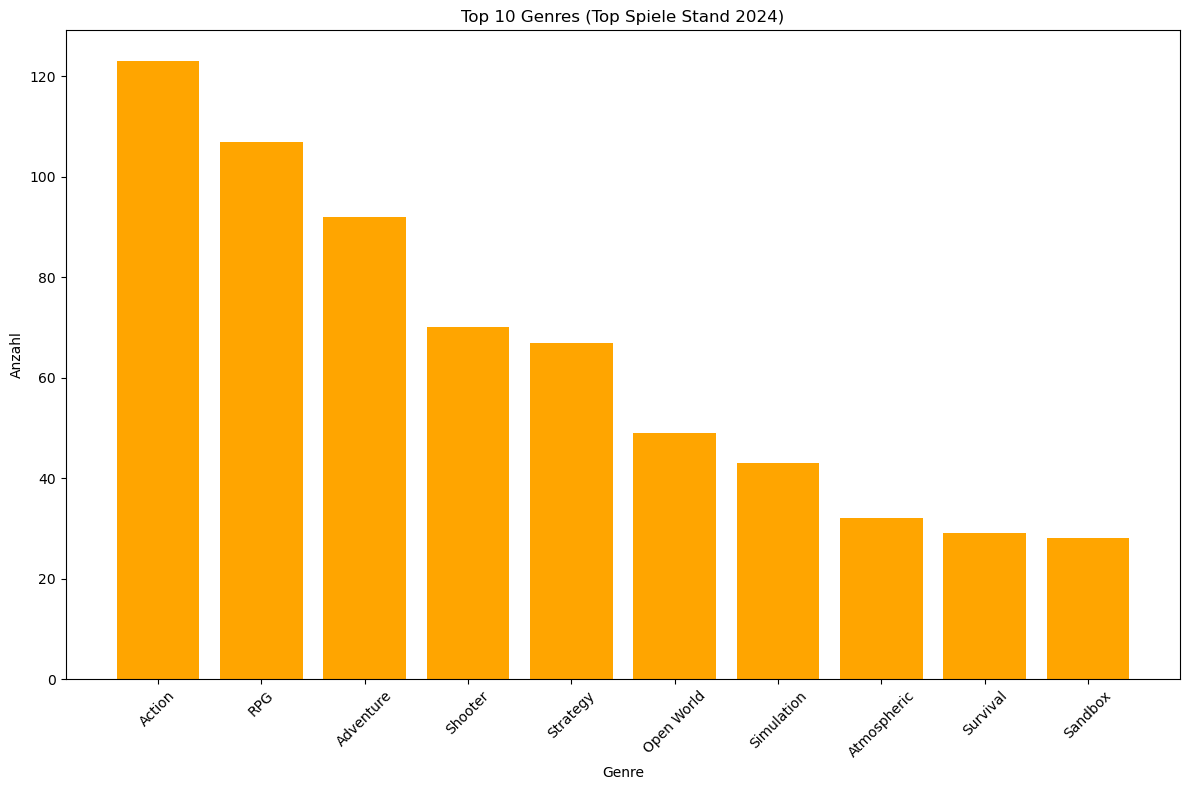

In [5]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

data = pd.read_csv("genre_count.csv")

data = data.dropna(subset=["Genre"])

data["Count"] = pd.to_numeric(data["Count"], errors="coerce")

genre_mapping = {
    "Action RPG": ["RPG", "Action"],
    "Western RPG": ["RPG", "Western"],
    "Strategy RPG": ["RPG", "Strategy"],
    "Open World RPG": ["RPG", "Open World"],
    "MMORPG": ["RPG", "MMO"],
    "JRPG": ["RPG"],
    "Action-Adventure": ["Action", "Adventure"],
    "Open-World Action": ["Action", "Open World"],
    "Action Adventure": ["Action", "Adventure"],
    "Action Adventure": ["Action", "Adventure"],
    "Tactical RPG": ["RPG", "Tactical"],
    "Turn-Based Strategy": ["Strategy", "Turn-Based"],
    "Real-Time Strategy": ["Strategy", "Real-Time"],
    "Grand Strategy": ["Strategy"],
    "4X Strategy": ["Strategy"],
    "Adventure Game": ["Adventure"],
    "First-Person Shooter": ["Shooter"],
    "Third-Person Shooter": ["Shooter"],
    "Hero Shooter": ["Shooter"],
    "Looter Shooter": ["Shooter"],
    "Tactical FPS": ["Shooter", "Tactical"],
    "FPS": ["Shooter"],
    "Puzzle Game": ["Puzzle"],
    "Open World Survival Craft": ["Open World", "Survival", "Craft"],
    "Survival Horror": ["Survival", "Horror"],
    "Dark Fantasy": ["Fantasy"],

}

def map_genre(genre):
    if genre in genre_mapping:
        return genre_mapping[genre] 
    return [genre]  


data["Mapped Genre"] = data["Genre"].apply(map_genre)
exploded_data = data.explode("Mapped Genre")  


genre_counts = Counter()
for _, row in exploded_data.iterrows():
    genres = row["Mapped Genre"]
    count = row["Count"]
    genre_counts[genres] += count

genre_count_df = pd.DataFrame.from_dict(genre_counts, orient="index", columns=["Count"])
genre_count_df = genre_count_df.sort_values(by="Count", ascending=False)
genre_count_df = genre_count_df[~genre_count_df.index.isin(["First-Person"])] 
# Nur die Top 10 Genres auswählen
top_10_genres = genre_count_df.head(10)

plt.figure(figsize=(12, 8))
plt.bar(top_10_genres.index, top_10_genres["Count"], color="orange")
plt.title("Top 10 Genres (Top Spiele Stand 2024)")
plt.xlabel("Genre")
plt.ylabel("Anzahl")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [7]:
#Diese Grafik zeigt die zehn beliebtesten Spielegenres unter den Top Spielen auf Basis der Anzahl der Spiel Titel.
#Action- und RPG-Spiele dominieren die Liste, gefolgt von Adventure und Shooter. 
#Dies bestätigt die anhaltende Popularität dieser Genres, die sich besonders für umfangreiche und immersive Spielerfahrungen eignen.
#Interessanterweise sind auch Strategietitel und Simulationen vertreten, was darauf hindeutet,
#dass auch komplexere Spielmechaniken eine stabile Fanbasis haben.

In [9]:
import glob

file_paths = glob.glob("./PriceScoreCSV/*.csv") 

dataframes = [pd.read_csv(file) for file in file_paths]

combined_data = pd.concat(dataframes, ignore_index=True)


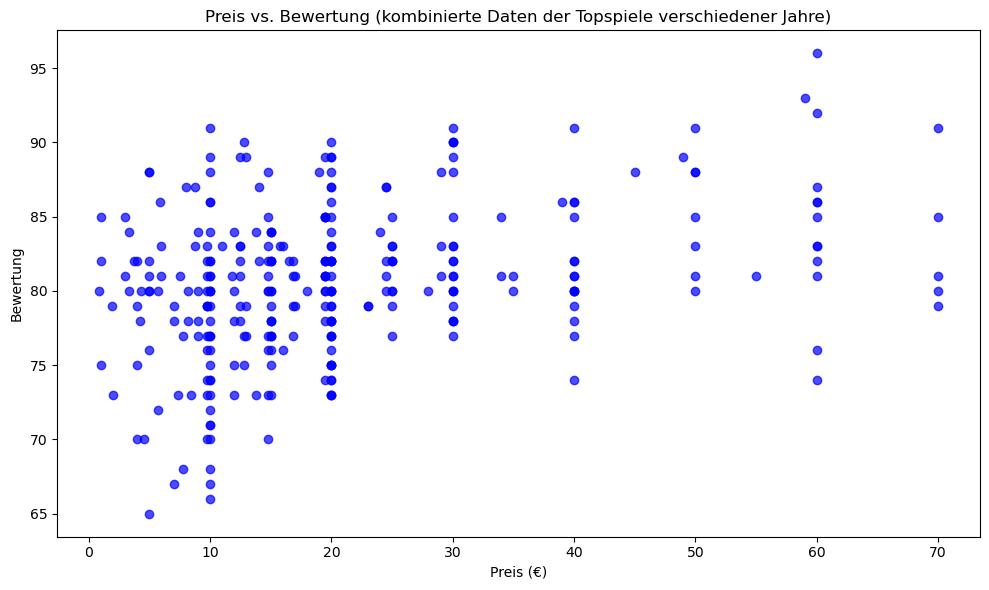

In [11]:
def clean_price(price):
    if isinstance(price, str):
        price = price.replace("€", "").replace("$", "").replace("CDN$", "").replace(",", ".").strip()
        try:
            return float(price)
        except ValueError:
            return None
    return None

combined_data["Price"] = combined_data["Price"].apply(clean_price)

combined_data["MetaScore"] = pd.to_numeric(combined_data["MetaScore"], errors="coerce")

combined_data = combined_data.dropna(subset=["Price", "MetaScore"])


plt.figure(figsize=(10, 6))
plt.scatter(combined_data["Price"], combined_data["MetaScore"], alpha=0.7, c="blue")
plt.title("Preis vs. Bewertung (kombinierte Daten der Topspiele verschiedener Jahre)")
plt.xlabel("Preis (€)")
plt.ylabel("Bewertung")
plt.tight_layout()
plt.show()

In [13]:
#Dieser Scatterplott visualisiert den Zusammenhang zwischen Preis und Bewertung der Top Spiele. 
#Es lässt sich erkennen, dass es keine starke direkte Korrelation zwischen hohen Preisen und besseren Bewertungen gibt.
#Viele Spiele mit mittleren oder niedrigeren Preisen erhalten ebenfalls hohe Bewertungen, was darauf hindeutet,
#dass Qualität nicht zwangsläufig an einen höheren Preis gebunden ist. Dennoch gibt es einige teurere Spiele mit sehr hohen Bewertungen, 
#was darauf hinweisen könnte, dass Premium-Titel mit großem Budget tendenziell gut abschneiden.


In [15]:
file_paths = glob.glob("./PriceScoreCSV/*.csv")  

dataframes = []

for file in file_paths:
    year = file.split("_")[-1].split(".")[0] 
    df = pd.read_csv(file)
    df["Release Year"] = int(year)  
    dataframes.append(df)

combined_data = pd.concat(dataframes, ignore_index=True)


In [17]:
main_genres = [
    "Action", "RPG", "Adventure", "Shooter", "Platformer", "Puzzle",
    "Strategy", "Simulation", "Horror", "Sports", "Fighting", "Arcade",
    "Roguelike", "Survival", "Music", "Party", "Story"
]

def map_genres_auto(genre, main_genres):
    if not isinstance(genre, str):
        return ["Andere"]
    
    mapped = []
    
    for sub_genre in genre.split(", "):
        for main_genre in main_genres:
            if main_genre.lower() in sub_genre.lower():  
                mapped.append(main_genre)
    return list(set(mapped))  

combined_data["Mapped Genres"] = combined_data["Genres"].apply(lambda g: map_genres_auto(g, main_genres))

exploded_data = combined_data.explode("Mapped Genres")
unmapped_genres = combined_data[combined_data["Mapped Genres"].apply(lambda x: "Andere" in x)]["Genres"].unique()
print("Nicht-gemappte Genres:", unmapped_genres)


Nicht-gemappte Genres: [nan]


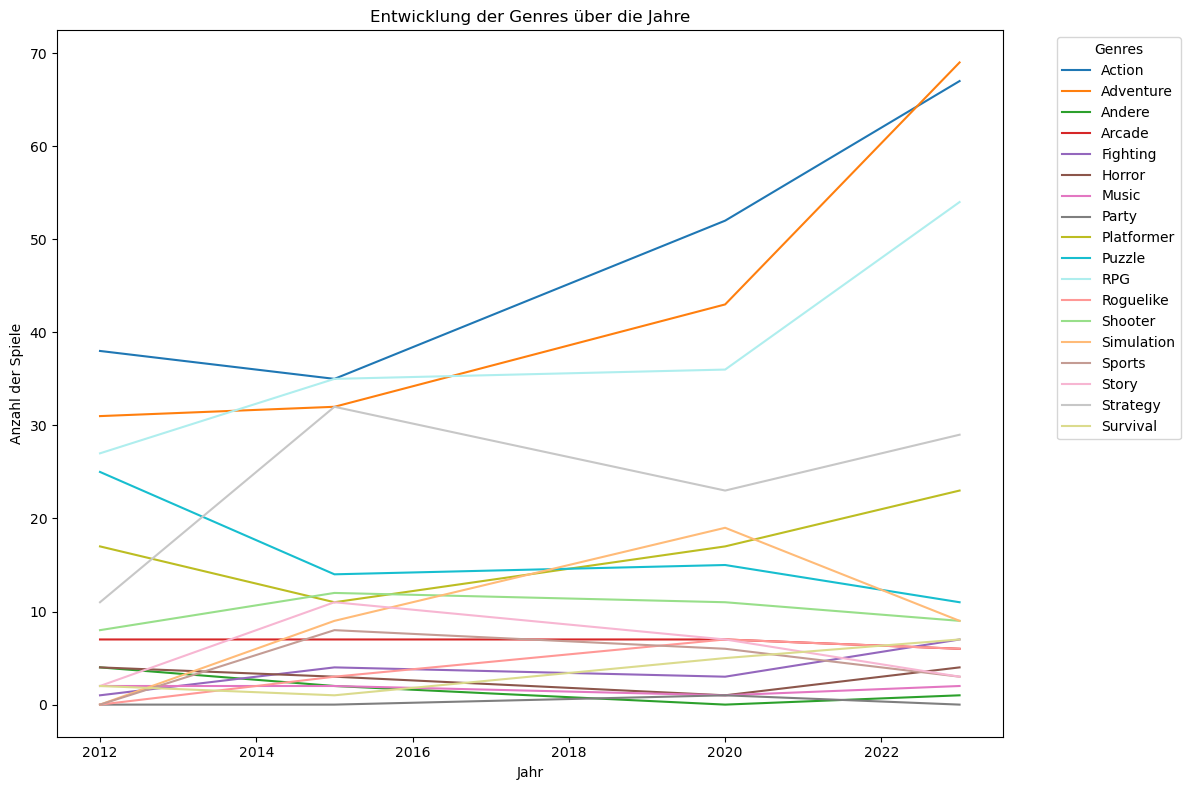

In [19]:
genre_trends = exploded_data.groupby(["Release Year", "Mapped Genres"]).size().unstack(fill_value=0)
custom_colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf",
    "#AFEEEE", "#ff9896", "#98df8a", "#ffbb78", "#c49c94",
    "#f7b6d2", "#c7c7c7", "#dbdb8d", "#9edae5", "#17becf"
]
genre_trends.plot(figsize=(12, 8), color=custom_colors)
plt.title("Entwicklung der Genres über die Jahre")
plt.xlabel("Jahr")
plt.ylabel("Anzahl der Spiele")
plt.legend(title="Genres", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [21]:
#Dieses Liniendiagramm zeigt die Entwicklung der verschiedenen Spielegenres die in den Topspielen vorkommen über die Jahre hinweg.
#Dabei ist zu erkennen, dass einige Genres, insbesondere Action, Adventure und RPG, im Laufe der Jahre an Beliebtheit gewonnen haben.
#Während bestimmte Genres wie Shooter konstant bleiben, sind andere Genres wie Puzzle weniger präsent wurden. 
#Dies deutet darauf hin, dass sich die Vorlieben der Spieler im Laufe der Zeit verändern,
#wobei heutezutage actionlastige und storybasierte Spiele an Bedeutung gewinnen.

C:\Users\sohel\AppData\Local\Temp\ipykernel_16792\2023408086.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data["Release Year"] = filtered_data["Release Year"].astype(int)
C:\Users\sohel\AppData\Local\Temp\ipykernel_16792\2023408086.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Release Year", y="Price", data=filtered_data, palette="Set2", showfliers=False)  # Ohne Outlier


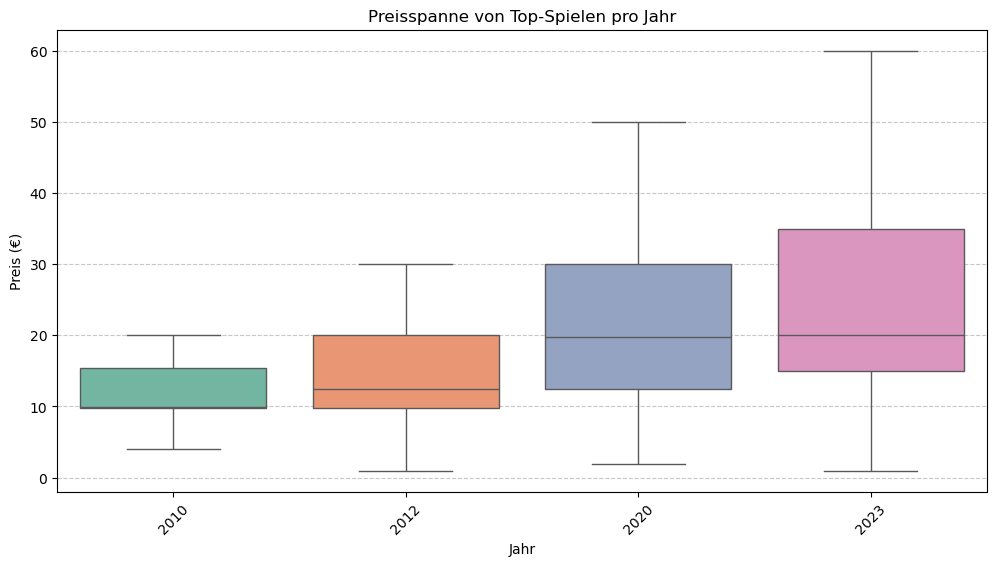

In [23]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_paths = glob.glob("./PriceScoreCSV/*.csv")

dataframes = [pd.read_csv(file) for file in file_paths]
combined_data = pd.concat(dataframes, ignore_index=True)

def clean_price(price):
    if isinstance(price, str):
        price = price.replace("€", "").replace("$", "").replace("CDN$", "").replace(",", ".").strip()
        try:
            return float(price)
        except ValueError:
            return None
    return None
combined_data["Price"] = combined_data["Price"].apply(clean_price)

if "Release Year" not in combined_data.columns and "Release Date" in combined_data.columns:
    combined_data["Extracted Year"] = combined_data["Release Date"].str.extract(r'(\d{4})')
    combined_data["Release Year"] = pd.to_numeric(combined_data["Extracted Year"], errors="coerce")
    combined_data.drop(columns=["Extracted Year"], inplace=True)  

filtered_data = combined_data.dropna(subset=["Price", "Release Year"])
filtered_data["Release Year"] = filtered_data["Release Year"].astype(int)

plt.figure(figsize=(12, 6))
sns.boxplot(x="Release Year", y="Price", data=filtered_data, palette="Set2", showfliers=False)  

plt.title("Preisspanne von Top-Spielen pro Jahr")
plt.xlabel("Jahr")
plt.ylabel("Preis (€)")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


In [24]:
#Der Boxplot zeigt, dass die Preise von Top-Spielen im Laufe der Jahre gestiegen sind.
#Während der Medianpreis der Topspiele in Früheren Jahren noch bei etwa 10 bis 20 Euro lag, hat er sich bis 2023 auf über 30 bis Euro erhöht.
#Dies deutet darauf hin, dass nichtnur Spiele insgesamt teurer geworden sind sondern die Topspiele der Gamer auch.
#Dies schlussfolgert auch das sich die Preisspanne im Laufe der Jahre vergrößert hat.
#Während in den früheren Jahren die top Spiele in einem relativ engen Preisbereich lagen, zeigt sich insbesondere im Jahr 2020 eine größere Varianz. 
#Es gibt sowohl sehr günstige Top-Spiele für unter 10 Euro als auch hochpreisige AAA-Titel, die 50 bis 60 Euro oder mehr kosten.

In [27]:
#Zusammenfassend zeigen die Grafiken, dass sich die Spieleindustrie dynamisch entwickelt: Während bestimmte Genres an Beliebtheit gewinnen, 
#bleibt der Markt für verschiedene Spielerpräferenzen breit gefächert. Gleichzeitig zeigt sich,
#dass teure Spiele nicht zwangsläufig besser bewertet werden, und die Preisentwicklung deutet darauf hin, 
#dass unterschiedliche Monetarisierungsstrategien eingesetzt werden, um verschiedene Zielgruppen zu bedienen.